# NGC 253 four-channel PN inference — v3.0

This version matches the v3.0 training preprocessing and evaluation decisions:

- no whole-image sigma clipping before the training `asinh + z-score` transform;
- non-finite pixels are replaced only as a safety measure;
- peak finding uses the same `scipy.ndimage.maximum_filter` implementation as
  the training notebook;
- catalogue matching is treated as **positive-reference recovery**, not a
  precision/false-positive ground truth;
- catalogue recovery is swept over 1–4 pixels before quoting a working
  completeness value.

`MATCH_TOLERANCE = 2.0` below is a **provisional diagnostic radius**. Inspect
the recovery-vs-radius curve and localization diagnostics before using a final
radius in the thesis analysis.


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from scipy.ndimage import maximum_filter
from tensorflow import keras

MODEL_PATH = "best_PN_UNet_focal_all_grouped_v3.0.keras"
FITS_PATH = "../NGC253_4channel.fits"
NORM_PATH = "PN_UNet_normalization_v3.0.npz"
CATALOG_PATH = "../PN_CAT.csv"
ORIGINAL_FITS_PATH = "/Users/golta/Desktop/Uni/Thesis/ADP.2025-07-06T07_52_11.876.fits"

TILE_SIZE = 64
STRIDE = 32
BATCH_SIZE = 32
MIN_DISTANCE = 3

# Catalogue matching is a recovery/completeness diagnostic only.
MATCH_TOLERANCE_GRID = np.array([1.0, 1.5, 2.0, 2.5, 3.0, 4.0])
MATCH_TOLERANCE = 2.0  # provisional; calibrate from the sweep below

LINE_NAMES = ["Hbeta", "OIII5007", "Halpha", "NII6584"]
SNR_COL = "OIII_SNR"
FWHM_COL = "FWHM"
M5007_COL = "m5007"
OIII_BKG_COL = "OIII_BKG"
HA_BKG_COL = "HA_BKG"

norm=np.load(NORM_PATH,allow_pickle=True)

FLUX_SCALE=float(norm["flux_scale"])
asinh_scale=norm["asinh_scale"].astype(np.float32)
CHANNEL_MEANS=norm["channel_means"].astype(np.float32)
CHANNEL_STDS=norm["channel_stds"].astype(np.float32)
PEAK_THRESHOLD=float(norm["detection_threshold"])

print("FLUX_SCALE:", FLUX_SCALE)
print("CHANNEL_MEANS:", CHANNEL_MEANS)
print("CHANNEL_STDS:", CHANNEL_STDS)
print("PEAK_THRESHOLD:", PEAK_THRESHOLD)

model = keras.models.load_model(MODEL_PATH, compile=False)
print("Model input shape :", model.input_shape)
print("Model output shape:", model.output_shape)

FLUX_SCALE: 1e+18
CHANNEL_MEANS: [0.46611422 0.48516408 0.41826382 0.388465  ]
CHANNEL_STDS: [0.5128561  0.42062527 0.5263107  0.45978034]
PEAK_THRESHOLD: 0.45000000000000007
Model input shape : (None, 64, 64, 4)
Model output shape: (None, 64, 64, 1)


In [26]:
with fits.open(FITS_PATH) as hdul:
    data = hdul[0].data

data = np.squeeze(np.asarray(data, dtype=np.float32))
print("Original FITS shape:", data.shape)

if data.ndim != 3:
    raise ValueError(f"Expected a 3D FITS array, got shape {data.shape}")

if data.shape[-1] == 4:
    image = data
elif data.shape[0] == 4:
    image = np.moveaxis(data, 0, -1)
else:
    raise ValueError(f"Could not find the 4-channel axis. FITS shape is {data.shape}")

print("Image shape used by network:", image.shape)
assert image.shape[-1] == 4

print("Expected channel order:")
for i, name in enumerate(LINE_NAMES):
    print(i, name)

Original FITS shape: (1733, 6080, 4)
Image shape used by network: (1733, 6080, 4)
Expected channel order:
0 Hbeta
1 OIII5007
2 Halpha
3 NII6584


In [27]:
def replace_nonfinite_channels(image):
    """Replace only NaN/Inf values; do not clip finite astrophysical signal."""
    clean = image.astype(np.float32, copy=True)

    for c in range(clean.shape[-1]):
        channel = clean[:, :, c]
        valid = np.isfinite(channel)

        if not np.any(valid):
            raise ValueError(f"Channel {c} contains no finite values.")

        n_invalid = int(np.sum(~valid))
        replacement = float(np.median(channel[valid]))
        channel[~valid] = replacement

        print(
            f"Channel {c}: invalid replaced={n_invalid}, "
            f"replacement median={replacement:.4e}"
        )

    return clean


# 1. Safety repair only. No sigma clipping: finite real-image values are kept.
image_clean = replace_nonfinite_channels(image)

# 2. Exactly the saved training transform.
image_scaled = image_clean * np.float32(FLUX_SCALE)

image_transformed = np.arcsinh(
    image_scaled / asinh_scale[None, None, :]
)

image_norm = (
    image_transformed - CHANNEL_MEANS[None, None, :]
) / CHANNEL_STDS[None, None, :]

image_norm = image_norm.astype(np.float32)

if not np.all(np.isfinite(image_norm)):
    raise ValueError("Normalized image still contains NaN or Inf values.")

print("\nFinal normalized image statistics:")
for c, name in enumerate(norm["line_names"]):
    x = image_norm[:, :, c]
    print(
        f"{name}: "
        f"mean={x.mean():.3f}, "
        f"std={x.std():.3f}, "
        f"min={x.min():.3f}, "
        f"max={x.max():.3f}"
    )


Channel 0: invalid replaced=2099462, replacement median=9.9090e-19
Channel 1: invalid replaced=2098866, replacement median=7.4025e-19
Channel 2: invalid replaced=2098718, replacement median=2.5497e-18
Channel 3: invalid replaced=2098612, replacement median=1.3745e-18

Final normalized image statistics:
Hbeta: mean=0.086, std=0.962, min=-0.909, max=32.662
OIII5007: mean=0.180, std=1.179, min=-1.153, max=44.367
Halpha: mean=0.018, std=0.986, min=-0.795, max=22.854
NII6584: mean=0.022, std=0.972, min=-0.845, max=19.457


In [28]:
def get_start_positions(length, tile_size, stride):
    if length <= tile_size:
        return [0]

    positions = list(range(0, length - tile_size + 1, stride))
    final_position = length - tile_size
    if positions[-1] != final_position:
        positions.append(final_position)
    return positions


def predict_full_image(model, image, tile_size=64, stride=32, batch_size=32):
    height, width, channels = image.shape
    assert channels == 4

    pad_y = max(0, tile_size - height)
    pad_x = max(0, tile_size - width)
    if pad_y > 0 or pad_x > 0:
        image_padded = np.pad(image, ((0, pad_y), (0, pad_x), (0, 0)), mode="edge")
    else:
        image_padded = image

    padded_height, padded_width, _ = image_padded.shape
    y_positions = get_start_positions(padded_height, tile_size, stride)
    x_positions = get_start_positions(padded_width, tile_size, stride)
    coordinates = [(y, x) for y in y_positions for x in x_positions]
    print("Number of tiles:", len(coordinates))

    prediction_sum = np.zeros((padded_height, padded_width), dtype=np.float32)
    weight_sum = np.zeros((padded_height, padded_width), dtype=np.float32)

    w = np.hanning(tile_size).astype(np.float32)
    weight = 0.1 + 0.9 * np.outer(w, w)

    for start in range(0, len(coordinates), batch_size):
        batch_coords = coordinates[start:start + batch_size]
        batch = np.stack([
            image_padded[y:y + tile_size, x:x + tile_size, :]
            for y, x in batch_coords
        ])
        batch_predictions = model.predict(batch, verbose=0)[..., 0]

        for (y, x), pred in zip(batch_coords, batch_predictions):
            prediction_sum[y:y + tile_size, x:x + tile_size] += pred * weight
            weight_sum[y:y + tile_size, x:x + tile_size] += weight

    full_prediction = prediction_sum / np.maximum(weight_sum, 1e-12)
    return full_prediction[:height, :width]

In [29]:
pn_heatmap = predict_full_image(model, image_norm, tile_size=TILE_SIZE, stride=STRIDE, batch_size=BATCH_SIZE)
#pn_heatmap[~valid_mask] = 0.0

print("Final heatmap shape:", pn_heatmap.shape)
print("Prediction range:", pn_heatmap.min(), pn_heatmap.max())

Number of tiles: 10206
Final heatmap shape: (1733, 6080)
Prediction range: 2.7713909e-17 0.99533355


In [30]:
def find_pn_centers(heatmap, threshold=0.30, min_distance=3):
    """Same local-maximum implementation used by the training notebook."""
    size = 2 * min_distance + 1
    local_max = heatmap == maximum_filter(
        heatmap,
        size=size,
        mode="constant",
    )
    detected = local_max & (heatmap >= threshold)

    y, x = np.where(detected)
    scores = heatmap[y, x]
    order = np.argsort(scores)[::-1]

    return np.column_stack([x[order], y[order], scores[order]])


detections = find_pn_centers(
    pn_heatmap,
    threshold=PEAK_THRESHOLD,
    min_distance=MIN_DISTANCE,
)

print("Number of PN candidates:", len(detections))
print("\n[x, y, score]")
for detection in detections:
    print(detection)


Number of PN candidates: 10391

[x, y, score]
[4.34400000e+03 9.52000000e+02 9.95333552e-01]
[5.29500000e+03 6.94000000e+02 9.93711591e-01]
[3.91000000e+03 1.25000000e+03 9.93090212e-01]
[5.17000000e+03 6.69000000e+02 9.88369048e-01]
[5.15400000e+03 1.07500000e+03 9.87683177e-01]
[3.45800000e+03 1.18700000e+03 9.82765734e-01]
[4.99400000e+03 1.51500000e+03 9.82324481e-01]
[4.79600000e+03 6.13000000e+02 9.81690288e-01]
[2.54700000e+03 1.08900000e+03 9.81430352e-01]
[4.54800000e+03 1.08000000e+03 9.80350971e-01]
[3.88100000e+03 8.13000000e+02 9.80023503e-01]
[5.08300000e+03 8.49000000e+02 9.79985654e-01]
[2.06600000e+03 3.72000000e+02 9.74476457e-01]
[3.60600000e+03 1.00400000e+03 9.73088682e-01]
[5.65600000e+03 5.97000000e+02 9.72645998e-01]
[2.57300000e+03 7.39000000e+02 9.72576499e-01]
[1.58100000e+03 9.46000000e+02 9.72449541e-01]
[3.07800000e+03 9.48000000e+02 9.72285271e-01]
[2.34200000e+03 1.56000000e+02 9.71897721e-01]
[4.66000000e+03 5.95000000e+02 9.70612466e-01]
[3.53600000e+0

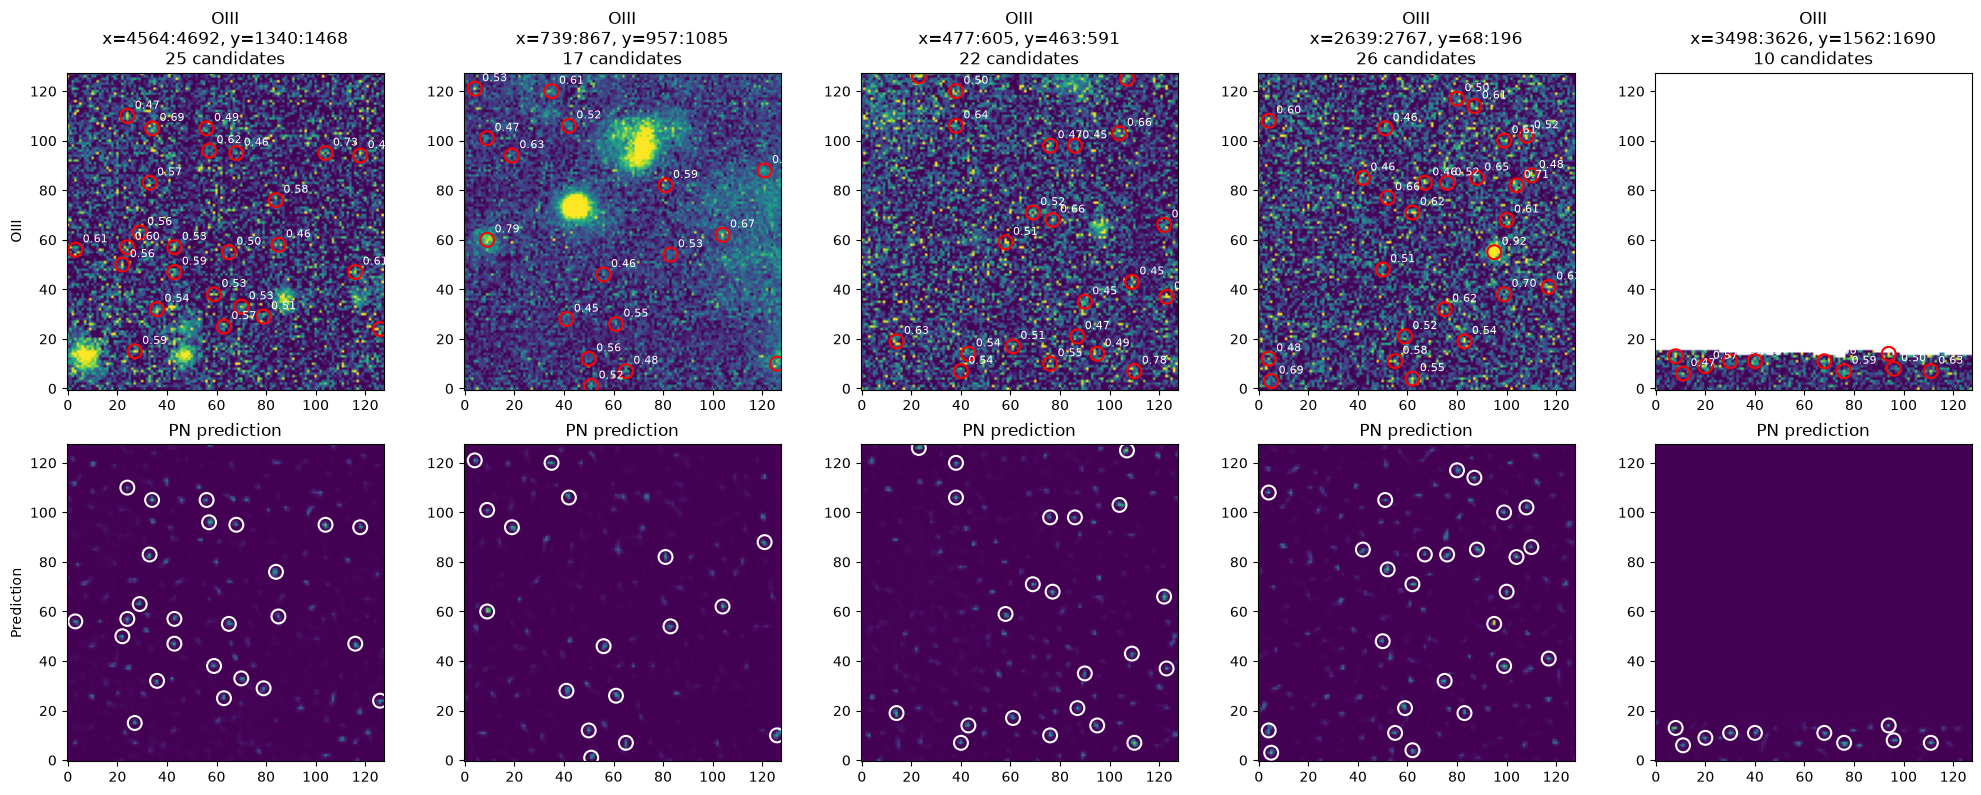

In [31]:
def plot_random_cutouts(image, pn_heatmap, detections, n_cutouts=6, cutout_size=128, seed=42, threshold=0.20):
    rng = np.random.default_rng(seed)
    height, width, _ = image.shape
    oiii = image[..., 1]

    _, axes = plt.subplots(2, n_cutouts, figsize=(4 * n_cutouts, 8))
    if n_cutouts == 1:
        axes = axes[:, None]

    for i in range(n_cutouts):
        x0 = rng.integers(0, max(1, width - cutout_size))
        y0 = rng.integers(0, max(1, height - cutout_size))
        x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]

        inside = (
            (detections[:, 0] >= x0) & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0) & (detections[:, 1] < y1)
            & (detections[:, 2] >= threshold))
        det = detections[inside]

        if len(det) > 0:
            local_x = det[:, 0] - x0
            local_y = det[:, 1] - y0

        finite = oiii_cutout[np.isfinite(oiii_cutout)]
        if len(finite) > 0:
            vmin, vmax = np.percentile(finite, 5), np.percentile(finite, 99)
        else:
            vmin, vmax = 0, 1

        ax = axes[0, i]
        ax.imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
        if len(det) > 0:
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="red", s=100, linewidths=1.5)
            for x, y, score in zip(local_x, local_y, det[:, 2]):
                ax.text(x + 3, y + 3, f"{score:.2f}", color="white", fontsize=8)
        ax.set_title(f"OIII\nx={x0}:{x1}, y={y0}:{y1}\n{len(det)} candidates")

        ax = axes[1, i]
        ax.imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
        if len(det) > 0:
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="white", s=100, linewidths=1.5)
        ax.set_title("PN prediction")

    axes[0, 0].set_ylabel("OIII")
    axes[1, 0].set_ylabel("Prediction")
    plt.tight_layout()
    plt.show()


plot_random_cutouts(
    image=image, pn_heatmap=pn_heatmap, detections=detections,
    n_cutouts=5, cutout_size=128, seed=100)

In [32]:
pn_catalog = pd.read_csv(CATALOG_PATH)
print(pn_catalog.head())
print("Number of catalogue PNe:", len(pn_catalog))

with fits.open(ORIGINAL_FITS_PATH) as hdul:
    wcs = WCS(hdul["OIII5006_FLUX"].header).celestial

ra = pn_catalog["RAdeg"].to_numpy()
dec = pn_catalog["DEdeg"].to_numpy()
catalog_x, catalog_y = wcs.world_to_pixel_values(ra, dec)
pn_catalog["x"] = catalog_x
pn_catalog["y"] = catalog_y

print(pn_catalog[["ID", "RAdeg", "DEdeg", "x", "y"]].head())

height, width, _ = image.shape
inside_image = (
    np.isfinite(pn_catalog["x"]) & np.isfinite(pn_catalog["y"])
    & (pn_catalog["x"] >= 0) & (pn_catalog["x"] < width)
    & (pn_catalog["y"] >= 0) & (pn_catalog["y"] < height))

catalog_in_image = pn_catalog[inside_image].copy()
print(f"Catalogue PNe inside image: {len(catalog_in_image)} / {len(pn_catalog)}")

   ID      RAdeg      DEdeg   FWHM  log_OIII_Hb  log_NII_Ha  log_SII_Ha  \
0   1  11.987615 -25.221952  0.956     1.871572    0.028113   -1.241971   
1   2  11.994759 -25.220211  0.923     1.776825   -0.548196   -1.497087   
2   3  12.021884 -25.194207  0.786     1.073425   -0.153119   -2.029765   
3   4  11.992403 -25.218152  1.080     1.436248   -0.857334   -0.846140   
4   5  11.990650 -25.220049  1.083     1.405052   -0.738616   -0.659834   

    m5007  OIII_SNR  OIII_BKG     HA_BKG  use_NII  use_SII  
0  24.724    95.148  4635.374   8483.608    False    False  
1  25.008    81.816  5043.334   8932.815    False    False  
2  24.709   132.907  3856.435  15246.028     True    False  
3  25.433    48.006  4647.829  12368.687    False    False  
4  25.789    37.488  5518.461  12392.201    False    False  
Number of catalogue PNe: 571
   ID      RAdeg      DEdeg            x           y
0   1  11.987615 -25.221952  1048.627172  768.130699
1   2  11.994759 -25.220211   938.519031  719.19

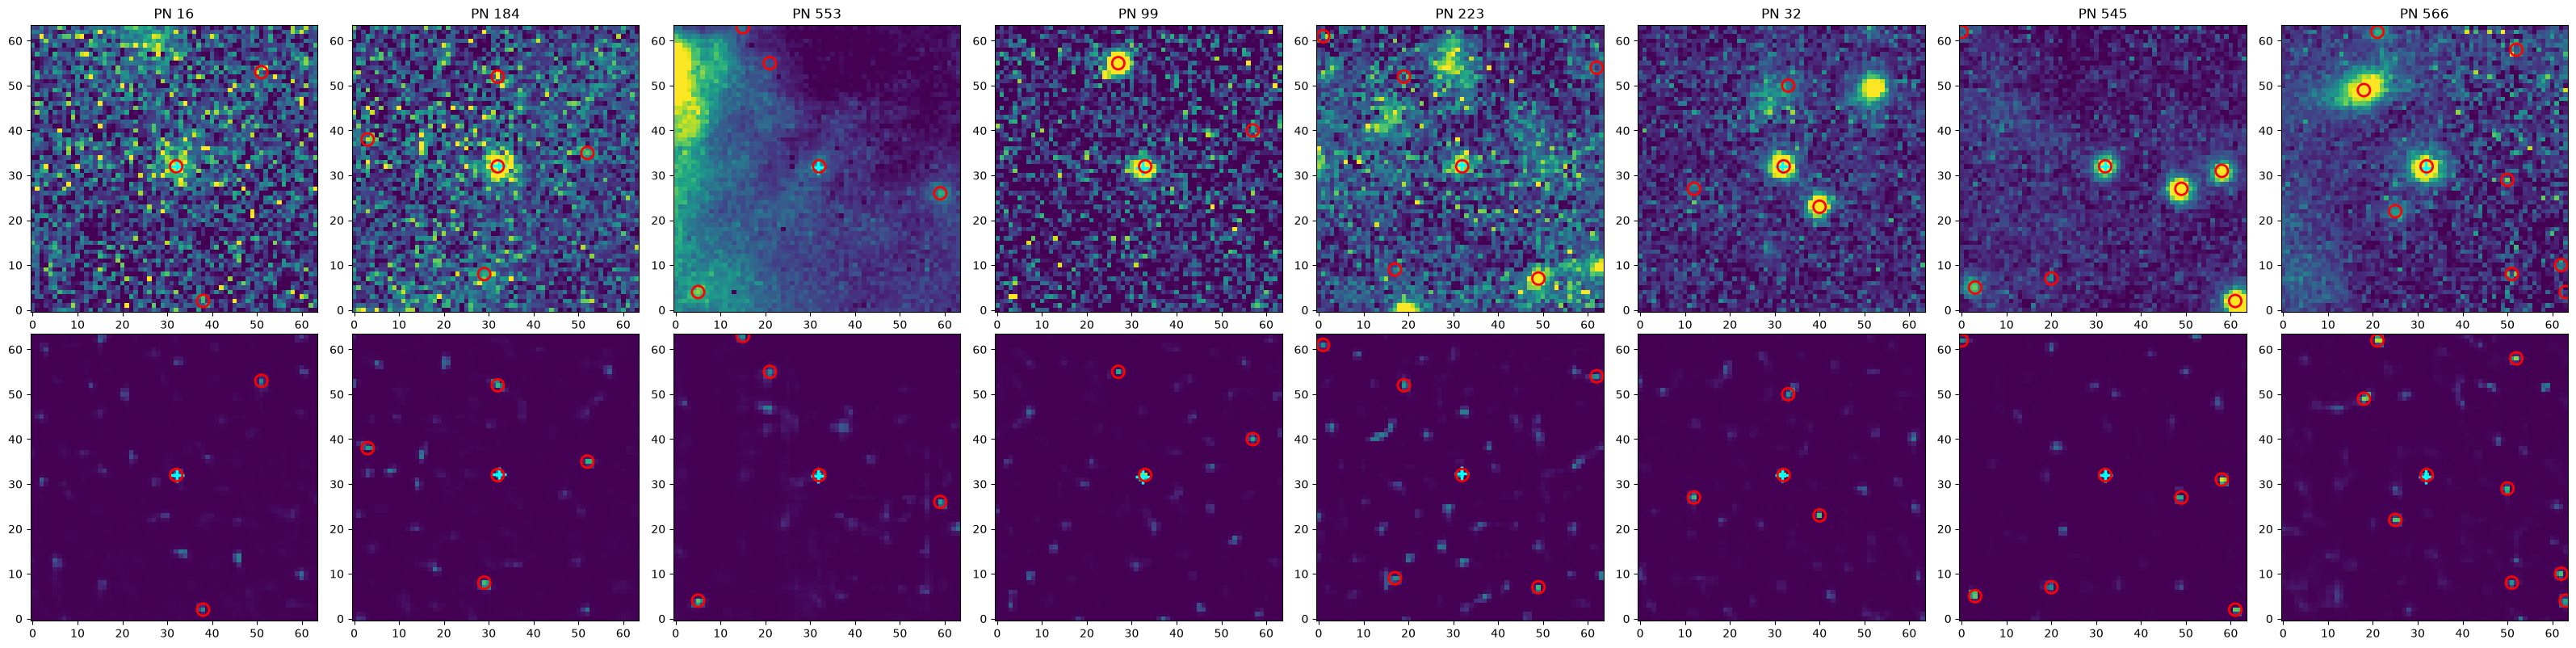

In [33]:
def plot_catalog_pn_cutouts(image, pn_heatmap, detections, catalog, n_cutouts=8, cutout_size=64, seed=42, threshold=0.20):
    rng = np.random.default_rng(seed)
    height, width, _ = image.shape
    oiii = image[..., 1]

    n = min(n_cutouts, len(catalog))
    selected_indices = rng.choice(len(catalog), size=n, replace=False)
    selected = catalog.iloc[selected_indices]
    _, axes = plt.subplots(2, n, figsize=(4 * n, 8))
    if n == 1:
        axes = axes[:, None]

    half = cutout_size // 2
    for i, (_, pn) in enumerate(selected.iterrows()):
        xc, yc = pn["x"], pn["y"]
        x0 = max(0, min(int(round(xc)) - half, width - cutout_size))
        y0 = max(0, min(int(round(yc)) - half, height - cutout_size))
        x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]
        cat_x, cat_y = xc - x0, yc - y0

        inside = (
            (detections[:, 0] >= x0) & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0) & (detections[:, 1] < y1)
            & (detections[:, 2] >= threshold))
        det = detections[inside]
        model_x, model_y = det[:, 0] - x0, det[:, 1] - y0

        finite = oiii_cutout[np.isfinite(oiii_cutout)]
        if len(finite):
            vmin, vmax = np.percentile(finite, 8), np.percentile(finite, 99)
        else:
            vmin, vmax = 0, 1

        axes[0, i].imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
        axes[0, i].scatter(cat_x, cat_y, marker="+", s=180, linewidths=2.5, c="cyan")
        if len(det):
            axes[0, i].scatter(model_x, model_y, facecolors="none", edgecolors="red", s=120, linewidths=2)
        axes[0, i].set_title(f"PN {int(pn['ID'])}")

        axes[1, i].imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
        axes[1, i].scatter(cat_x, cat_y, marker="+", s=180, linewidths=2.5, c="cyan")
        if len(det):
            axes[1, i].scatter(model_x, model_y, facecolors="none", edgecolors="red", s=120, linewidths=2)

    plt.tight_layout()
    plt.show()


plot_catalog_pn_cutouts(
    image=image, pn_heatmap=pn_heatmap, detections=detections,
    catalog=catalog_in_image, n_cutouts=8, cutout_size=64, seed=60)

,tolerance_pix,n_catalog_matched,n_catalog_missed,catalog_completeness,n_unmatched_candidates,new_catalog_matches
0,1.0,451,120,0.789842,9940,451.0
1,1.5,479,92,0.838879,9912,28.0
2,2.0,480,91,0.840630,9911,1.0
3,2.5,481,90,0.842382,9910,1.0
4,3.0,482,89,0.844133,9909,1.0
5,4.0,482,89,0.844133,9909,0.0


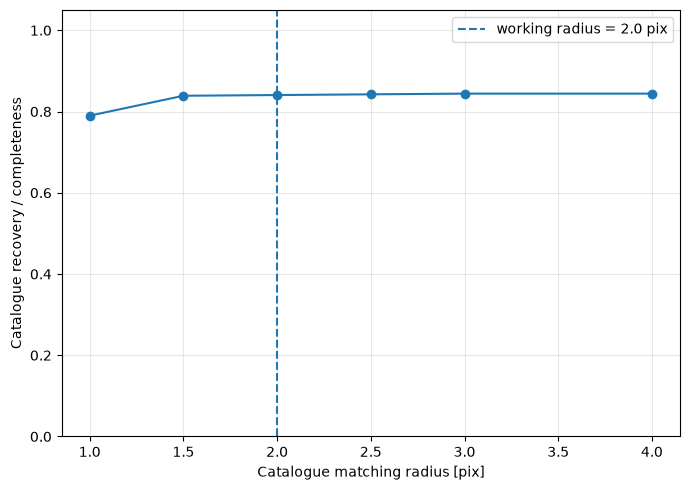

Use the sweep to calibrate the final matching radius. Do not choose a radius solely because it maximizes completeness.
CATALOGUE PN RECOVERY
Working matching radius      : 2.00 pix
Catalogue PNe inside image   : 571
Catalogue PNe recovered      : 480
Catalogue PNe not recovered  : 91
Catalogue completeness       : 0.841 (84.1%)
Unmatched model candidates   : 9911 (NOT automatically false positives)

Missed catalogue PNe:


,ID,RAdeg,DEdeg,x,y
11,12,11.995105,-25.228126,1023.897314,605.000000
14,15,11.990313,-25.215240,938.394439,834.307171
23,24,11.965393,-25.208480,1177.000000,1184.407984
29,30,11.907014,-25.226603,2121.000000,1529.470996
40,41,11.858656,-25.261645,3129.802743,1534.678198
50,51,11.845509,-25.289539,3612.000000,1279.000000
68,69,11.810142,-25.326802,4481.279107,1119.489226
78,79,11.755981,-25.349892,5427.771443,1350.209247
79,80,11.778650,-25.347630,5115.394030,1150.085263
86,87,11.750809,-25.364486,5658.316295,1198.748807


In [34]:
def match_catalog_to_detections(catalog, detections, tolerance):
    """One-to-one nearest-pair catalogue recovery matching.

    The catalogue is treated as a positive reference set. A model detection
    that is not matched to the catalogue is returned as an *unmatched
    candidate*, not as a false positive, because catalogue completeness is not
    assumed.
    """
    catalog = catalog.copy()
    cat_xy = catalog[["x", "y"]].to_numpy(dtype=np.float32)
    det = np.asarray(detections, dtype=np.float32)

    matched_catalog_indices = set()
    matched_detection_indices = set()
    accepted_pairs = []

    if len(catalog) > 0 and len(det) > 0:
        det_xy = det[:, :2]

        dx = cat_xy[:, None, 0] - det_xy[None, :, 0]
        dy = cat_xy[:, None, 1] - det_xy[None, :, 1]
        distances = np.sqrt(dx**2 + dy**2)

        candidate_pairs = np.argwhere(distances <= tolerance)

        if len(candidate_pairs) > 0:
            pair_distances = distances[
                candidate_pairs[:, 0],
                candidate_pairs[:, 1],
            ]
            order = np.argsort(pair_distances)

            for pair_index in order:
                cat_index, det_index = candidate_pairs[pair_index]

                cat_index = int(cat_index)
                det_index = int(det_index)

                if cat_index in matched_catalog_indices:
                    continue
                if det_index in matched_detection_indices:
                    continue

                matched_catalog_indices.add(cat_index)
                matched_detection_indices.add(det_index)
                accepted_pairs.append(
                    (
                        cat_index,
                        det_index,
                        float(distances[cat_index, det_index]),
                    )
                )

    matched = np.zeros(len(catalog), dtype=bool)
    matched_detection_x = np.full(len(catalog), np.nan)
    matched_detection_y = np.full(len(catalog), np.nan)
    matched_detection_score = np.full(len(catalog), np.nan)
    matched_distance = np.full(len(catalog), np.nan)
    matched_detection_index = np.full(len(catalog), -1, dtype=int)

    for cat_index, det_index, distance in accepted_pairs:
        matched[cat_index] = True
        matched_detection_x[cat_index] = det[det_index, 0]
        matched_detection_y[cat_index] = det[det_index, 1]
        matched_detection_score[cat_index] = det[det_index, 2]
        matched_distance[cat_index] = distance
        matched_detection_index[cat_index] = det_index

    catalog["detected_by_model"] = matched
    catalog["matched_x"] = matched_detection_x
    catalog["matched_y"] = matched_detection_y
    catalog["matched_score"] = matched_detection_score
    catalog["match_distance_pix"] = matched_distance
    catalog["matched_detection_index"] = matched_detection_index

    matched_catalog = catalog[catalog["detected_by_model"]].copy()
    missed_catalog = catalog[~catalog["detected_by_model"]].copy()

    unmatched_mask = np.ones(len(det), dtype=bool)
    if matched_detection_indices:
        unmatched_mask[list(matched_detection_indices)] = False

    unmatched_detections = det[unmatched_mask].copy()

    return matched_catalog, missed_catalog, unmatched_detections


# ------------------------------------------------------------
# Matching-radius diagnostic
# ------------------------------------------------------------
recovery_rows = []

for tolerance in MATCH_TOLERANCE_GRID:
    matched_tmp, missed_tmp, unmatched_tmp = match_catalog_to_detections(
        catalog=catalog_in_image,
        detections=detections,
        tolerance=float(tolerance),
    )

    completeness_tmp = (
        len(matched_tmp) / len(catalog_in_image)
        if len(catalog_in_image)
        else np.nan
    )

    recovery_rows.append(
        {
            "tolerance_pix": float(tolerance),
            "n_catalog_matched": int(len(matched_tmp)),
            "n_catalog_missed": int(len(missed_tmp)),
            "catalog_completeness": float(completeness_tmp),
            "n_unmatched_candidates": int(len(unmatched_tmp)),
        }
    )

recovery_sweep = pd.DataFrame(recovery_rows)
recovery_sweep["new_catalog_matches"] = (
    recovery_sweep["n_catalog_matched"].diff().fillna(
        recovery_sweep["n_catalog_matched"]
    )
)

display(recovery_sweep)

plt.figure(figsize=(7, 5))
plt.plot(
    recovery_sweep["tolerance_pix"],
    recovery_sweep["catalog_completeness"],
    marker="o",
)
plt.axvline(
    MATCH_TOLERANCE,
    linestyle="--",
    label=f"working radius = {MATCH_TOLERANCE:.1f} pix",
)
plt.xlabel("Catalogue matching radius [pix]")
plt.ylabel("Catalogue recovery / completeness")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Use the sweep to calibrate the final matching radius. "
    "Do not choose a radius solely because it maximizes completeness."
)

# ------------------------------------------------------------
# Working catalogue-recovery view
# ------------------------------------------------------------
matched_catalog, missed_catalog, unmatched_detections = (
    match_catalog_to_detections(
        catalog=catalog_in_image,
        detections=detections,
        tolerance=MATCH_TOLERANCE,
    )
)

print("========================================")
print("CATALOGUE PN RECOVERY")
print("========================================")
print(f"Working matching radius      : {MATCH_TOLERANCE:.2f} pix")
print(f"Catalogue PNe inside image   : {len(catalog_in_image)}")
print(f"Catalogue PNe recovered      : {len(matched_catalog)}")
print(f"Catalogue PNe not recovered  : {len(missed_catalog)}")

completeness = (
    len(matched_catalog) / len(catalog_in_image)
    if len(catalog_in_image)
    else np.nan
)
print(
    f"Catalogue completeness       : "
    f"{completeness:.3f} ({100 * completeness:.1f}%)"
)

print(
    f"Unmatched model candidates   : {len(unmatched_detections)} "
    "(NOT automatically false positives)"
)

print("\nMissed catalogue PNe:")
display(
    missed_catalog[
        ["ID", "RAdeg", "DEdeg", "x", "y"]
    ].head(20)
)


Local maxima above 0.45: 10391
Catalogue PNe inside image: 571
Matching radius: 2.0 pixels


REAL-IMAGE THRESHOLD SWEEP
Threshold  Total detections  Catalogue recovered  Catalogue missed Completeness [%]  Unmatched candidates Detections / recovered PN
     0.45             10391                  480                91             84.1                  9911                     21.65
     0.60              3450                  382               189             66.9                  3068                      9.03
     0.70              1234                  308               263             53.9                   926                      4.01
     0.80               357                  203               368             35.6                   154                      1.76
     0.90               112                   87               484             15.2                    25                      1.29
     0.95                40                   30               541              5.3     

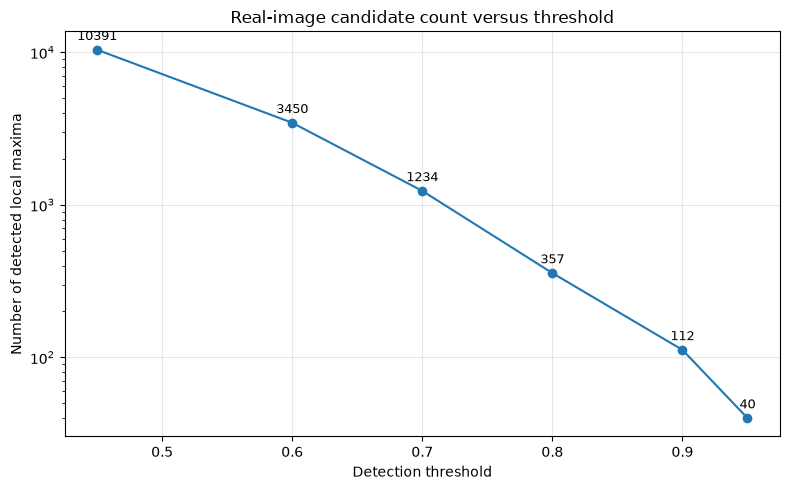

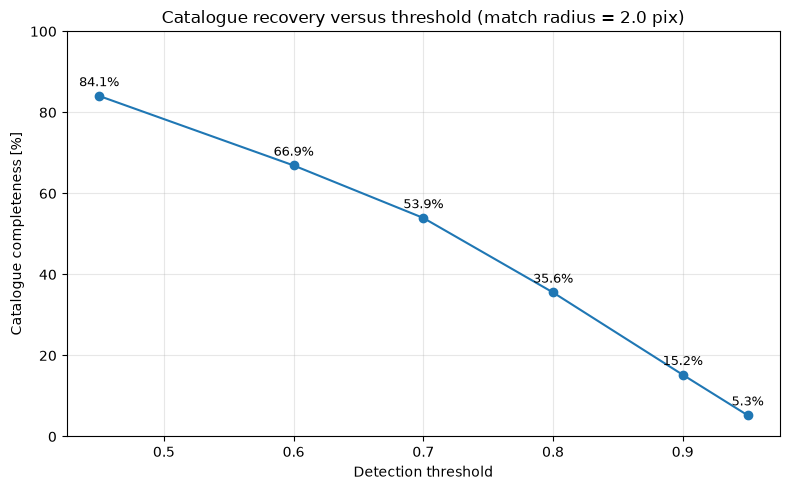

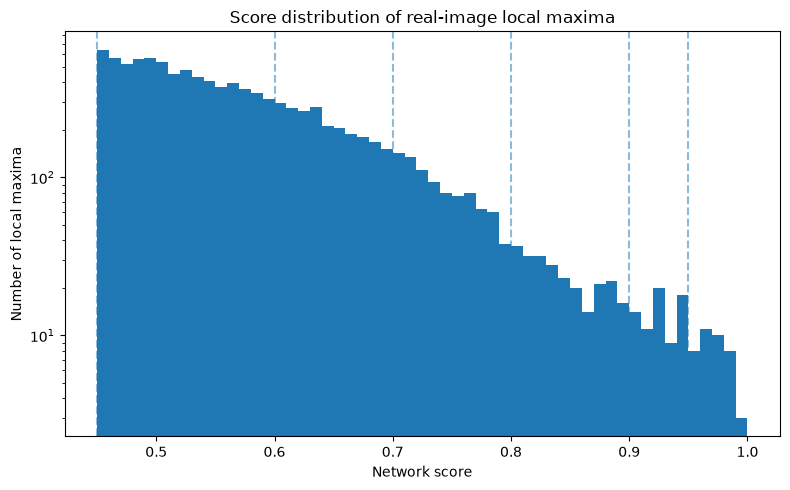

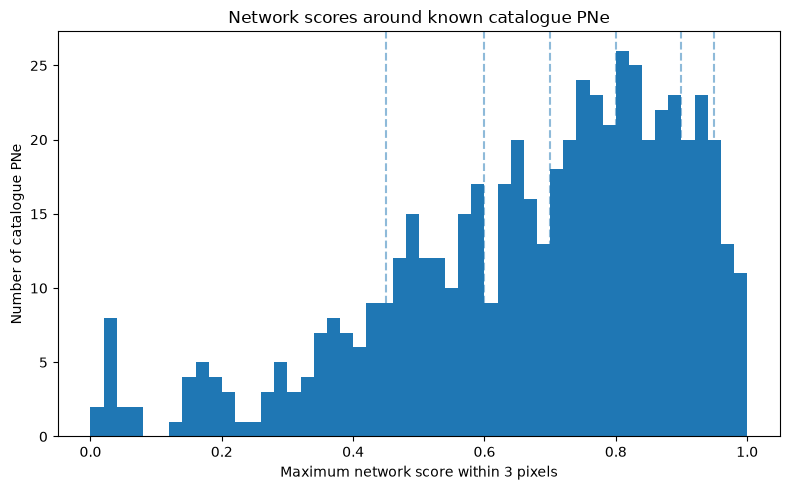


Network scores around catalogue PNe:
 5th percentile: 0.203
10th percentile: 0.366
25th percentile: 0.538
50th percentile: 0.725
75th percentile: 0.850
90th percentile: 0.928
95th percentile: 0.951

All real-image local maxima >= 0.45:
 5th percentile: 0.458
10th percentile: 0.467
25th percentile: 0.495
50th percentile: 0.551
75th percentile: 0.630
90th percentile: 0.714
95th percentile: 0.770
99th percentile: 0.906


In [35]:
# ============================================================
# REAL-IMAGE THRESHOLD SWEEP
# ============================================================
# Purpose:
#   Check whether the enormous number of PN candidates is mainly
#   caused by the operating threshold, or whether the network is
#   assigning high confidence to many real-image non-PN structures.
#
# IMPORTANT:
#   Catalogue is treated as a POSITIVE reference catalogue.
#   "Unmatched candidates" are NOT automatically called false positives.
# ============================================================

THRESHOLDS = np.array([
    0.45,
    0.60,
    0.70,
    0.80,
    0.90,
    0.95,
], dtype=float)

MATCH_RADIUS_FOR_SWEEP = 2.0   # pixels; keep fixed during threshold test


# ------------------------------------------------------------
# Find all local maxima once
# ------------------------------------------------------------
# Because the local-maximum definition does not depend on threshold,
# find everything above the lowest threshold once and then filter.
all_peaks = find_pn_centers(
    pn_heatmap,
    threshold=THRESHOLDS.min(),
    min_distance=MIN_DISTANCE,
)

print(f"Local maxima above {THRESHOLDS.min():.2f}: {len(all_peaks)}")
print(f"Catalogue PNe inside image: {len(catalog_in_image)}")
print(f"Matching radius: {MATCH_RADIUS_FOR_SWEEP:.1f} pixels")


# ------------------------------------------------------------
# Sweep thresholds
# ------------------------------------------------------------
rows = []

for threshold in THRESHOLDS:

    # Keep peaks above current threshold
    detections_t = all_peaks[
        all_peaks[:, 2] >= threshold
    ].copy()

    # Match detections to known catalogue PNe
    matched_t, missed_t, unmatched_t = match_catalog_to_detections(
        catalog=catalog_in_image,
        detections=detections_t,
        tolerance=MATCH_RADIUS_FOR_SWEEP,
    )

    n_det = len(detections_t)
    n_matched = len(matched_t)
    n_missed = len(missed_t)
    n_unmatched = len(unmatched_t)

    completeness = (
        n_matched / len(catalog_in_image)
        if len(catalog_in_image) > 0
        else np.nan
    )

    # How many total detections are produced for every recovered catalogue PN?
    det_per_recovered = (
        n_det / n_matched
        if n_matched > 0
        else np.nan
    )

    rows.append({
        "threshold": threshold,
        "N_detections": n_det,
        "N_catalog_recovered": n_matched,
        "N_catalog_missed": n_missed,
        "catalog_completeness": completeness,
        "N_unmatched_candidates": n_unmatched,
        "detections_per_recovered_PN": det_per_recovered,
    })


threshold_results = pd.DataFrame(rows)


# ------------------------------------------------------------
# Pretty print
# ------------------------------------------------------------
print("\n")
print("=" * 90)
print("REAL-IMAGE THRESHOLD SWEEP")
print("=" * 90)

display_table = threshold_results.copy()

display_table["catalog_completeness"] *= 100

display_table = display_table.rename(columns={
    "threshold": "Threshold",
    "N_detections": "Total detections",
    "N_catalog_recovered": "Catalogue recovered",
    "N_catalog_missed": "Catalogue missed",
    "catalog_completeness": "Completeness [%]",
    "N_unmatched_candidates": "Unmatched candidates",
    "detections_per_recovered_PN": "Detections / recovered PN",
})

print(
    display_table.to_string(
        index=False,
        formatters={
            "Threshold": "{:.2f}".format,
            "Completeness [%]": "{:.1f}".format,
            "Detections / recovered PN": "{:.2f}".format,
        },
    )
)


# ------------------------------------------------------------
# Plot 1: candidate count versus threshold
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results["threshold"],
    threshold_results["N_detections"],
    marker="o",
)

plt.yscale("log")
plt.xlabel("Detection threshold")
plt.ylabel("Number of detected local maxima")
plt.title("Real-image candidate count versus threshold")
plt.grid(alpha=0.3)

for _, row in threshold_results.iterrows():
    plt.annotate(
        f"{int(row['N_detections'])}",
        (row["threshold"], row["N_detections"]),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 2: catalogue completeness versus threshold
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results["threshold"],
    100 * threshold_results["catalog_completeness"],
    marker="o",
)

plt.xlabel("Detection threshold")
plt.ylabel("Catalogue completeness [%]")
plt.title(
    f"Catalogue recovery versus threshold "
    f"(match radius = {MATCH_RADIUS_FOR_SWEEP:.1f} pix)"
)
plt.ylim(0, 100)
plt.grid(alpha=0.3)

for _, row in threshold_results.iterrows():
    completeness_percent = 100 * row["catalog_completeness"]

    plt.annotate(
        f"{completeness_percent:.1f}%",
        (row["threshold"], completeness_percent),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 3: candidate score distribution
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))

plt.hist(
    all_peaks[:, 2],
    bins=np.linspace(0.45, 1.0, 56),
)

for threshold in THRESHOLDS:
    plt.axvline(
        threshold,
        linestyle="--",
        alpha=0.5,
    )

plt.xlabel("Network score")
plt.ylabel("Number of local maxima")
plt.yscale("log")
plt.title("Score distribution of real-image local maxima")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Extra diagnostic:
# How confident is the network about catalogue PNe themselves?
# ------------------------------------------------------------
catalog_peak_scores = []

SEARCH_RADIUS = 3  # pixels

for _, pn in catalog_in_image.iterrows():

    xc = int(round(pn["x"]))
    yc = int(round(pn["y"]))

    x0 = max(0, xc - SEARCH_RADIUS)
    x1 = min(pn_heatmap.shape[1], xc + SEARCH_RADIUS + 1)

    y0 = max(0, yc - SEARCH_RADIUS)
    y1 = min(pn_heatmap.shape[0], yc + SEARCH_RADIUS + 1)

    local_score = np.max(
        pn_heatmap[y0:y1, x0:x1]
    )

    catalog_peak_scores.append(local_score)

catalog_peak_scores = np.asarray(catalog_peak_scores)


plt.figure(figsize=(8, 5))

plt.hist(
    catalog_peak_scores,
    bins=np.linspace(0, 1, 51),
)

for threshold in THRESHOLDS:
    plt.axvline(
        threshold,
        linestyle="--",
        alpha=0.5,
    )

plt.xlabel("Maximum network score within 3 pixels")
plt.ylabel("Number of catalogue PNe")
plt.title("Network scores around known catalogue PNe")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Quantiles: very useful for diagnosing calibration
# ------------------------------------------------------------
print("\nNetwork scores around catalogue PNe:")
for q in [5, 10, 25, 50, 75, 90, 95]:
    print(
        f"{q:>2}th percentile: "
        f"{np.percentile(catalog_peak_scores, q):.3f}"
    )

print("\nAll real-image local maxima >= 0.45:")
for q in [5, 10, 25, 50, 75, 90, 95, 99]:
    print(
        f"{q:>2}th percentile: "
        f"{np.percentile(all_peaks[:, 2], q):.3f}"
    )

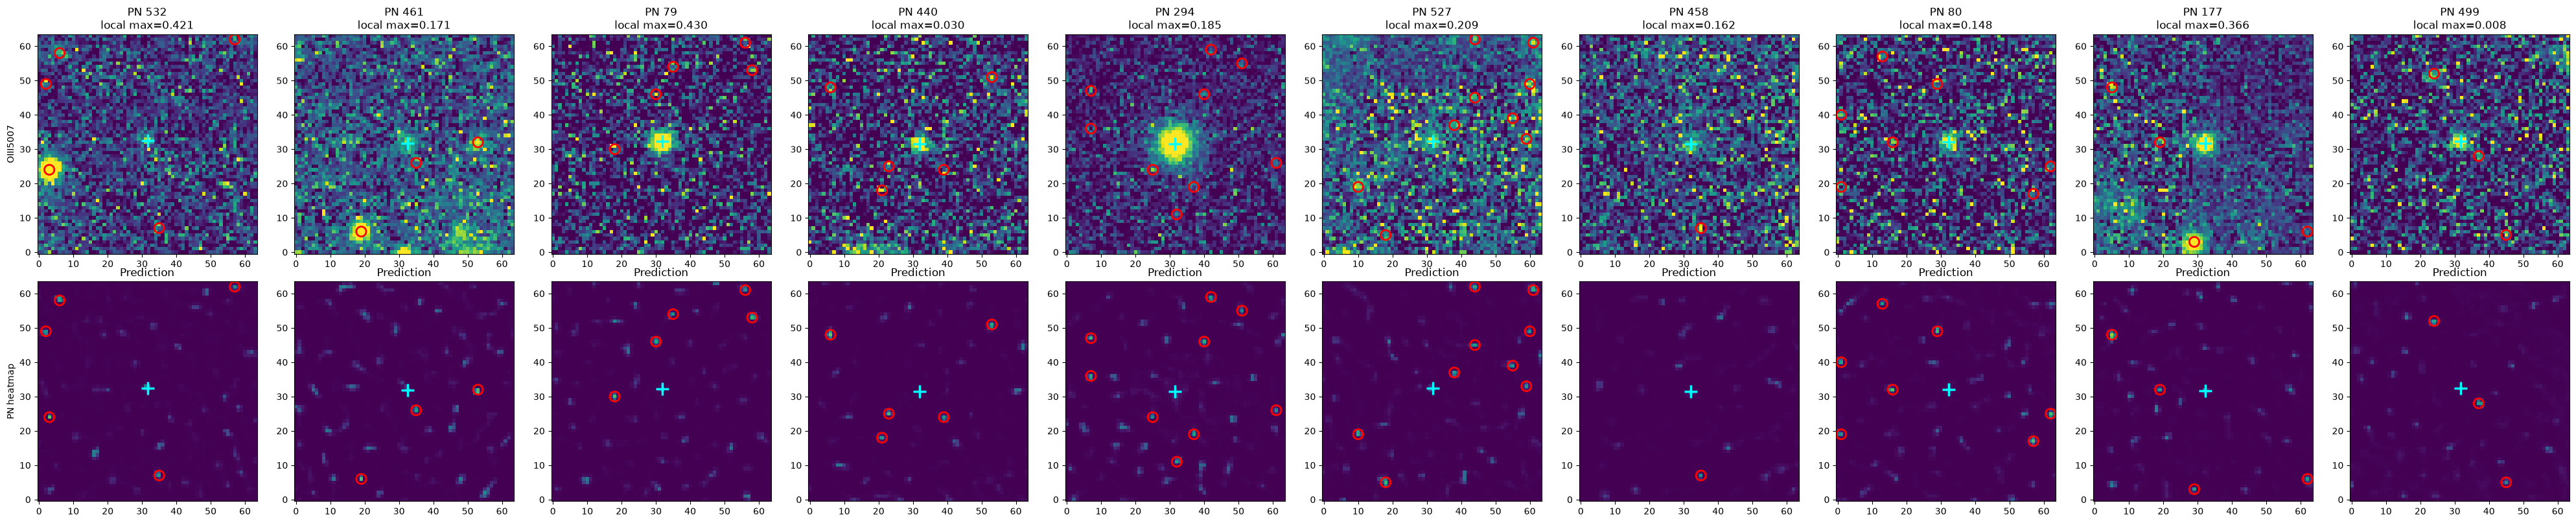

In [36]:
def plot_random_missed_pne(image, pn_heatmap, detections, missed_catalog, n_samples=10, cutout_size=64, seed=42):
    if len(missed_catalog) == 0:
        print("No missed catalogue PNe!")
        return

    rng = np.random.default_rng(seed)
    height, width, _ = image.shape
    oiii = image[..., 1]

    n = min(n_samples, len(missed_catalog))
    selected_indices = rng.choice(len(missed_catalog), size=n, replace=False)
    selected = missed_catalog.iloc[selected_indices]
    _, axes = plt.subplots(2, n, figsize=(4 * n, 8))
    if n == 1:
        axes = axes[:, None]

    half = cutout_size // 2
    for i, (_, pn) in enumerate(selected.iterrows()):
        xc, yc = float(pn["x"]), float(pn["y"])
        x0 = max(0, min(int(round(xc)) - half, width - cutout_size))
        y0 = max(0, min(int(round(yc)) - half, height - cutout_size))
        x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]
        cat_x, cat_y = xc - x0, yc - y0

        inside = (
            (detections[:, 0] >= x0) & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0) & (detections[:, 1] < y1))
        det = detections[inside]
        if len(det) > 0:
            local_det_x = det[:, 0] - x0
            local_det_y = det[:, 1] - y0

        search_radius = 3
        cx, cy = int(round(xc)), int(round(yc))
        sx0, sx1 = max(0, cx - search_radius), min(width, cx + search_radius + 1)
        sy0, sy1 = max(0, cy - search_radius), min(height, cy + search_radius + 1)
        local_max_score = np.max(pn_heatmap[sy0:sy1, sx0:sx1])

        finite = oiii_cutout[np.isfinite(oiii_cutout)]
        if len(finite) > 0:
            vmin, vmax = np.percentile(finite, 8), np.percentile(finite, 99)
        else:
            vmin, vmax = 0, 1

        ax = axes[0, i]
        ax.imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
        ax.scatter(cat_x, cat_y, marker="+", s=200, linewidths=2.5, c="cyan")
        if len(det) > 0:
            ax.scatter(local_det_x, local_det_y, facecolors="none", edgecolors="red", s=120, linewidths=2)
        ax.set_title(f"PN {pn['ID']}\nlocal max={local_max_score:.3f}")

        ax = axes[1, i]
        ax.imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
        ax.scatter(cat_x, cat_y, marker="+", s=200, linewidths=2.5, c="cyan")
        if len(det) > 0:
            ax.scatter(local_det_x, local_det_y, facecolors="none", edgecolors="red", s=120, linewidths=2)
        ax.set_title("Prediction")

    axes[0, 0].set_ylabel("OIII5007")
    axes[1, 0].set_ylabel("PN heatmap")
    plt.tight_layout()
    plt.show()


plot_random_missed_pne(
    image=image, pn_heatmap=pn_heatmap, detections=detections,
    missed_catalog=missed_catalog, n_samples=10, cutout_size=64, seed=42)

In [37]:
evaluated_catalog = pd.concat([matched_catalog, missed_catalog], ignore_index=True)
if "ID" in evaluated_catalog.columns:
    evaluated_catalog = evaluated_catalog.sort_values("ID").reset_index(drop=True)

print(evaluated_catalog.columns.tolist())
print("Detected:", evaluated_catalog["detected_by_model"].sum())
print("Missed:", (~evaluated_catalog["detected_by_model"]).sum())

['ID', 'RAdeg', 'DEdeg', 'FWHM', 'log_OIII_Hb', 'log_NII_Ha', 'log_SII_Ha', 'm5007', 'OIII_SNR', 'OIII_BKG', 'HA_BKG', 'use_NII', 'use_SII', 'x', 'y', 'detected_by_model', 'matched_x', 'matched_y', 'matched_score', 'match_distance_pix', 'matched_detection_index']
Detected: 480
Missed: 91


OIII S/N statistics
Detected: N=480, median=68.67, mean=77.03
Missed:   N=91, median=43.31, mean=48.92


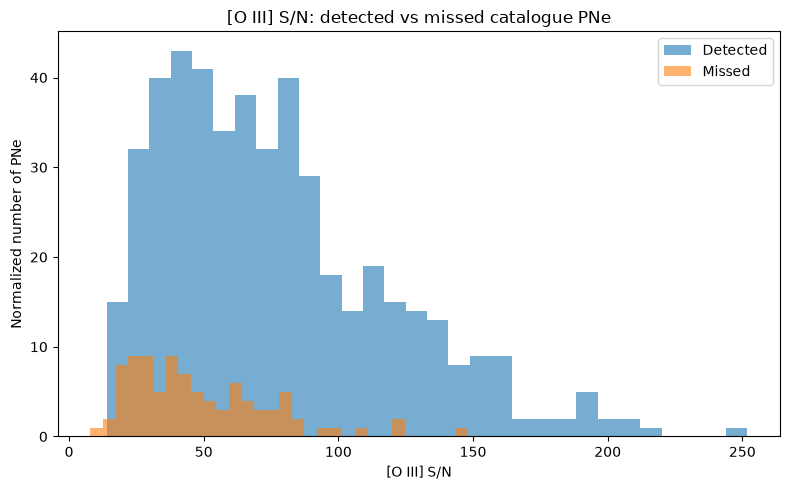

In [38]:
snr_data = evaluated_catalog[np.isfinite(evaluated_catalog[SNR_COL])].copy()
detected_snr = snr_data.loc[snr_data["detected_by_model"], SNR_COL]
missed_snr = snr_data.loc[~snr_data["detected_by_model"], SNR_COL]

print("OIII S/N statistics")
print("====================")
print(f"Detected: N={len(detected_snr)}, median={np.median(detected_snr):.2f}, mean={np.mean(detected_snr):.2f}")
print(f"Missed:   N={len(missed_snr)}, median={np.median(missed_snr):.2f}, mean={np.mean(missed_snr):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_snr, bins=30, alpha=0.6, density=False, label="Detected")
plt.hist(missed_snr, bins=30, alpha=0.6, density=False, label="Missed")
plt.xlabel("[O III] S/N")
plt.ylabel("Normalized number of PNe")
plt.title("[O III] S/N: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

,snr_bin,snr_median,snr_min,snr_max,n_total,n_detected,completeness
0,"(7.941999999999999, 29.588]",23.7235,7.943,29.580,72,45,0.625000
1,"(29.588, 39.928]",34.3230,29.612,39.766,71,56,0.788732
2,"(39.928, 50.03]",45.4180,40.090,49.946,71,58,0.816901
3,"(50.03, 63.627]",59.0285,50.058,63.627,72,59,0.819444
4,"(63.627, 78.328]",71.2990,63.653,78.257,71,61,0.859155
5,"(78.328, 93.237]",84.1190,78.540,93.231,71,64,0.901408
6,"(93.237, 124.521]",108.9750,93.243,124.476,71,66,0.929577
7,"(124.521, 251.791]",148.1835,124.536,251.791,72,71,0.986111


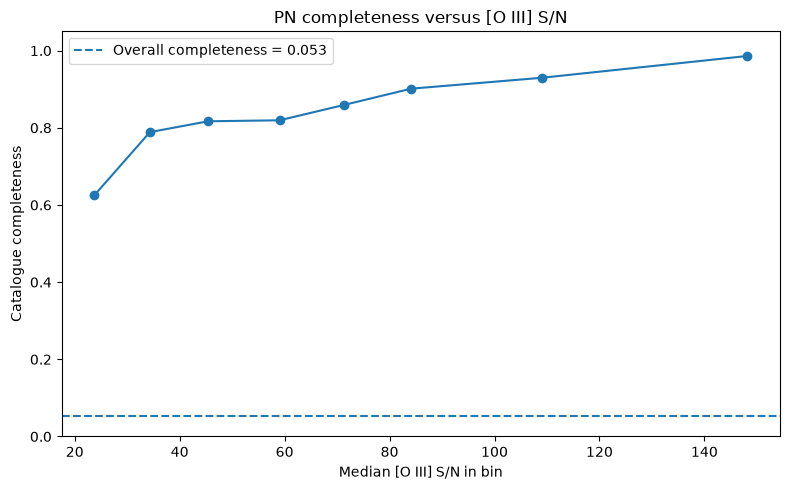

In [39]:
snr_data["snr_bin"] = pd.qcut(snr_data[SNR_COL], q=8, duplicates="drop")
snr_completeness = (
    snr_data.groupby("snr_bin", observed=True)
    .agg(
        snr_median=(SNR_COL, "median"),
        snr_min=(SNR_COL, "min"),
        snr_max=(SNR_COL, "max"),
        n_total=("detected_by_model", "size"),
        n_detected=("detected_by_model", "sum")).reset_index())
snr_completeness["completeness"] = snr_completeness["n_detected"] / snr_completeness["n_total"]
display(snr_completeness)

plt.figure(figsize=(8, 5))
plt.plot(snr_completeness["snr_median"], snr_completeness["completeness"], marker="o")
plt.axhline(completeness, linestyle="--", label=f"Overall completeness = {completeness:.3f}")
plt.xlabel("Median [O III] S/N in bin")
plt.ylabel("Catalogue completeness")
plt.ylim(0, 1.05)
plt.title("PN completeness versus [O III] S/N")
plt.legend()
plt.tight_layout()
plt.show()

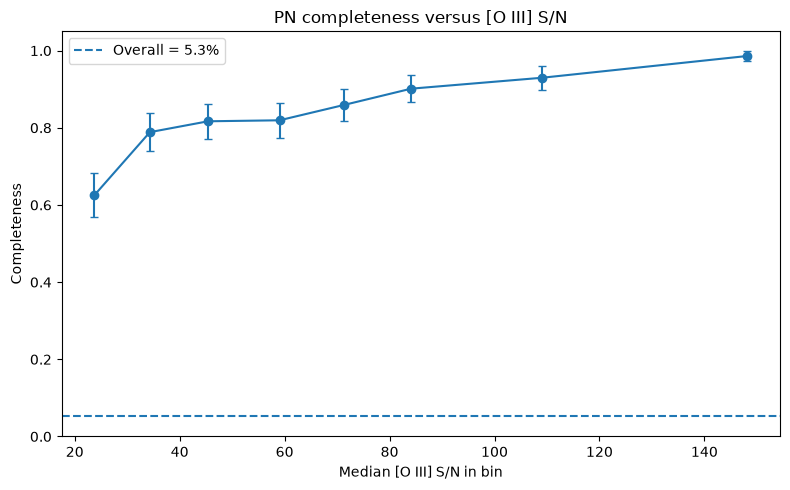

In [40]:
snr_completeness["error"] = np.sqrt(snr_completeness["completeness"] * 
                                    (1 - snr_completeness["completeness"]) / snr_completeness["n_total"])

plt.figure(figsize=(8, 5))
plt.errorbar(
    snr_completeness["snr_median"], snr_completeness["completeness"],
    yerr=snr_completeness["error"], marker="o", capsize=3)
plt.axhline(completeness, linestyle="--", label=f"Overall = {100 * completeness:.1f}%")
plt.xlabel("Median [O III] S/N in bin")
plt.ylabel("Completeness")
plt.ylim(0, 1.05)
plt.title("PN completeness versus [O III] S/N")
plt.legend()
plt.tight_layout()
plt.show()

FWHM statistics
Detected: N=480, median=0.756, mean=0.781
Missed:   N=91, median=0.793, mean=0.864


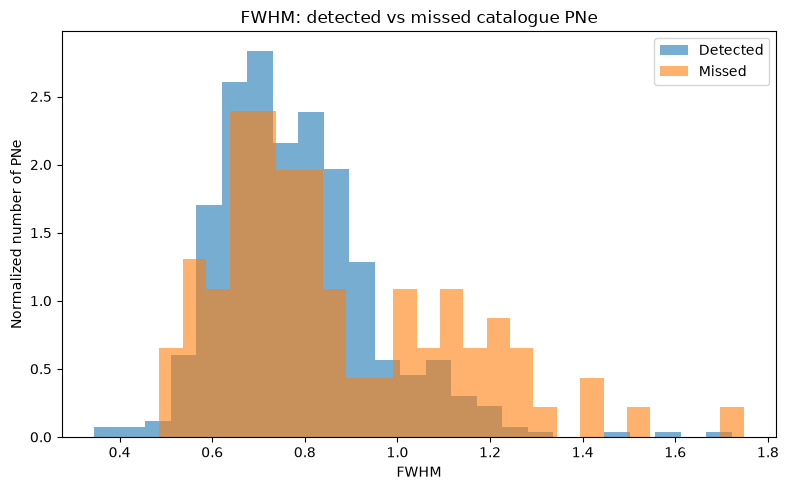

In [41]:
fwhm_data = evaluated_catalog[np.isfinite(evaluated_catalog[FWHM_COL])].copy()
detected_fwhm = fwhm_data.loc[fwhm_data["detected_by_model"], FWHM_COL]
missed_fwhm = fwhm_data.loc[~fwhm_data["detected_by_model"], FWHM_COL]

print("FWHM statistics")
print("===============")
print(f"Detected: N={len(detected_fwhm)}, median={np.median(detected_fwhm):.3f}, mean={np.mean(detected_fwhm):.3f}")
print(f"Missed:   N={len(missed_fwhm)}, median={np.median(missed_fwhm):.3f}, mean={np.mean(missed_fwhm):.3f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_fwhm, bins=25, alpha=0.6, density=True, label="Detected")
plt.hist(missed_fwhm, bins=25, alpha=0.6, density=True, label="Missed")
plt.xlabel("FWHM")
plt.ylabel("Normalized number of PNe")
plt.title("FWHM: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

,fwhm_bin,fwhm_median,fwhm_min,fwhm_max,n_total,n_detected,completeness,error
0,"(0.344, 0.616]",0.577,0.345,0.616,75,63,0.840000,0.042332
1,"(0.616, 0.662]",0.639,0.617,0.661,68,60,0.882353,0.039071
2,"(0.662, 0.709]",0.692,0.663,0.709,73,62,0.849315,0.041870
3,"(0.709, 0.76]",0.734,0.710,0.760,70,60,0.857143,0.041824
4,"(0.76, 0.821]",0.792,0.761,0.821,72,65,0.902778,0.034915
5,"(0.821, 0.876]",0.845,0.822,0.875,70,59,0.842857,0.043499
6,"(0.876, 1.012]",0.924,0.876,1.010,71,66,0.929577,0.030365
7,"(1.012, 1.748]",1.119,1.012,1.748,72,45,0.625000,0.057054


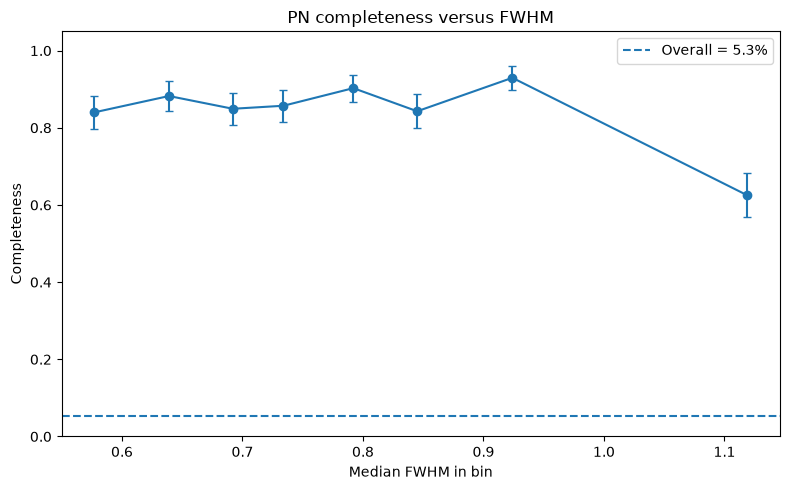

In [42]:
fwhm_data["fwhm_bin"] = pd.qcut(fwhm_data[FWHM_COL], q=8, duplicates="drop")
fwhm_completeness = (
    fwhm_data.groupby("fwhm_bin", observed=True)
    .agg(
        fwhm_median=(FWHM_COL, "median"),
        fwhm_min=(FWHM_COL, "min"),
        fwhm_max=(FWHM_COL, "max"),
        n_total=("detected_by_model", "size"),
        n_detected=("detected_by_model", "sum")).reset_index())
fwhm_completeness["completeness"] = fwhm_completeness["n_detected"] / fwhm_completeness["n_total"]
fwhm_completeness["error"] = np.sqrt(
    fwhm_completeness["completeness"] * (1 - fwhm_completeness["completeness"])
    / fwhm_completeness["n_total"]
)
display(fwhm_completeness)

plt.figure(figsize=(8, 5))
plt.errorbar(
    fwhm_completeness["fwhm_median"], fwhm_completeness["completeness"],
    yerr=fwhm_completeness["error"], marker="o", capsize=3
)
plt.axhline(completeness, linestyle="--", label=f"Overall = {100 * completeness:.1f}%")
plt.xlabel("Median FWHM in bin")
plt.ylabel("Completeness")
plt.ylim(0, 1.05)
plt.title("PN completeness versus FWHM")
plt.legend()
plt.tight_layout()
plt.show()


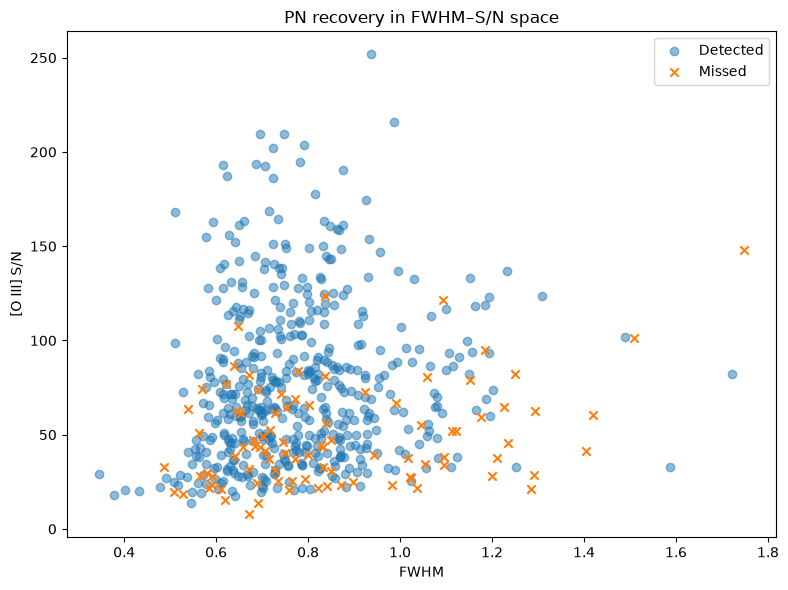

In [43]:
combined = evaluated_catalog[
    np.isfinite(evaluated_catalog[SNR_COL]) & np.isfinite(evaluated_catalog[FWHM_COL])
].copy()
det = combined["detected_by_model"]

plt.figure(figsize=(8, 6))
plt.scatter(combined.loc[det, FWHM_COL], combined.loc[det, SNR_COL], alpha=0.5, label="Detected")
plt.scatter(combined.loc[~det, FWHM_COL], combined.loc[~det, SNR_COL], marker="x", label="Missed")
plt.xlabel("FWHM")
plt.ylabel("[O III] S/N")
plt.title("PN recovery in FWHM–S/N space")
plt.legend()
plt.tight_layout()
plt.show()


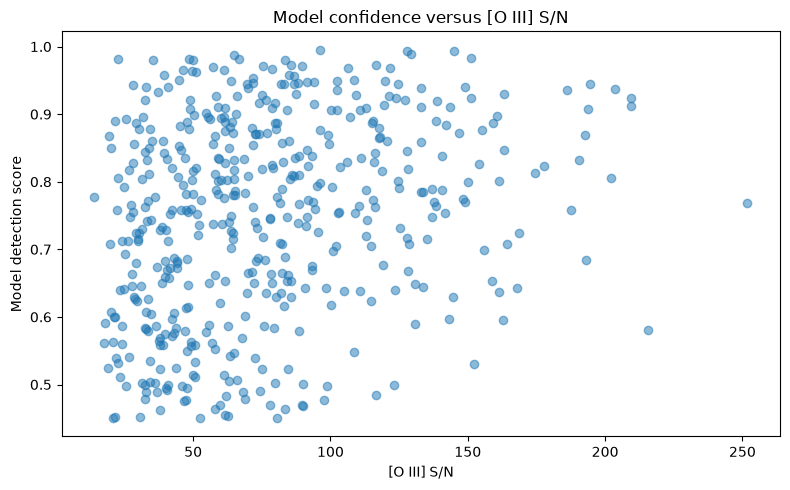

In [44]:
plt.figure(figsize=(8, 5))
plt.scatter(matched_catalog[SNR_COL], matched_catalog["matched_score"], alpha=0.5)
plt.xlabel("[O III] S/N")
plt.ylabel("Model detection score")
plt.title("Model confidence versus [O III] S/N")
plt.tight_layout()
plt.show()


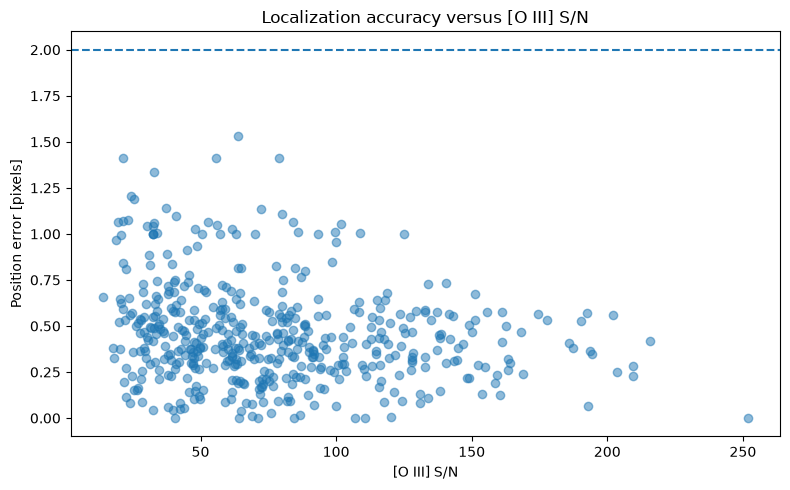

In [45]:
plt.figure(figsize=(8, 5))
plt.scatter(matched_catalog[SNR_COL], matched_catalog["match_distance_pix"], alpha=0.5)
plt.axhline(MATCH_TOLERANCE, linestyle="--")
plt.xlabel("[O III] S/N")
plt.ylabel("Position error [pixels]")
plt.title("Localization accuracy versus [O III] S/N")
plt.tight_layout()
plt.show()

OIII M5007 statistics
Detected: N=480, median=25.24, mean=25.28
Missed:   N=91, median=25.95, mean=25.87


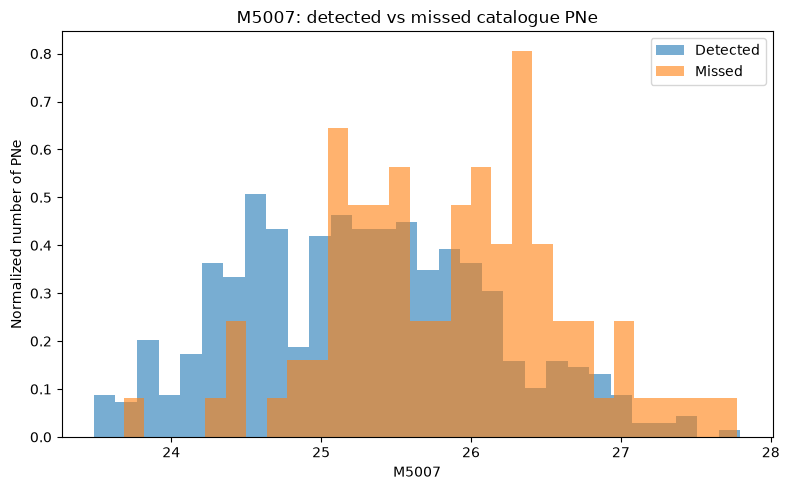

In [46]:
m5007_data = evaluated_catalog[np.isfinite(evaluated_catalog[M5007_COL])].copy()
detected_m5007 = m5007_data.loc[m5007_data["detected_by_model"], M5007_COL]
missed_m5007 = m5007_data.loc[~m5007_data["detected_by_model"], M5007_COL]

print("OIII M5007 statistics")
print("====================")
print(f"Detected: N={len(detected_m5007)}, median={np.median(detected_m5007):.2f}, mean={np.mean(detected_m5007):.2f}")
print(f"Missed:   N={len(missed_m5007)}, median={np.median(missed_m5007):.2f}, mean={np.mean(missed_m5007):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_m5007, bins=30, alpha=0.6, density=True, label="Detected")
plt.hist(missed_m5007, bins=30, alpha=0.6, density=True, label="Missed")
plt.xlabel("M5007")
plt.ylabel("Normalized number of PNe")
plt.title("M5007: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

OIII BKG statistics
Detected: N=480, median=4066.58, mean=4937.10
Missed:   N=91, median=3904.36, mean=5189.64
HA BKG statistics
Detected: N=480, median=17126.38, mean=26419.05
Missed:   N=91, median=14047.47, mean=22634.78


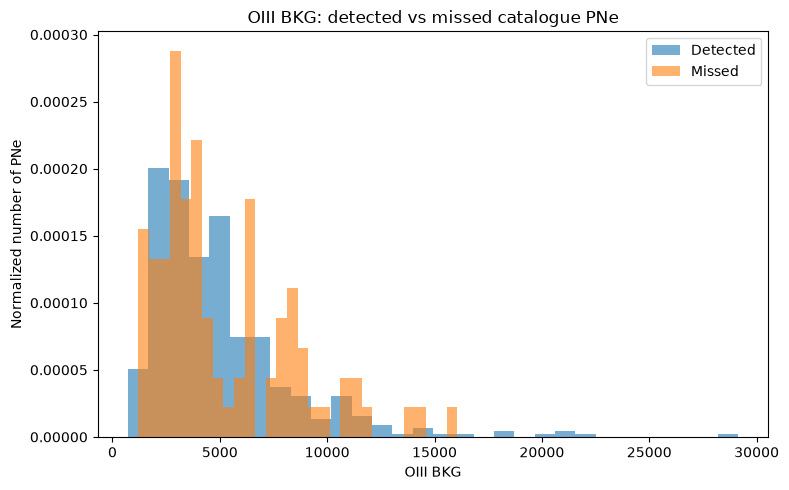

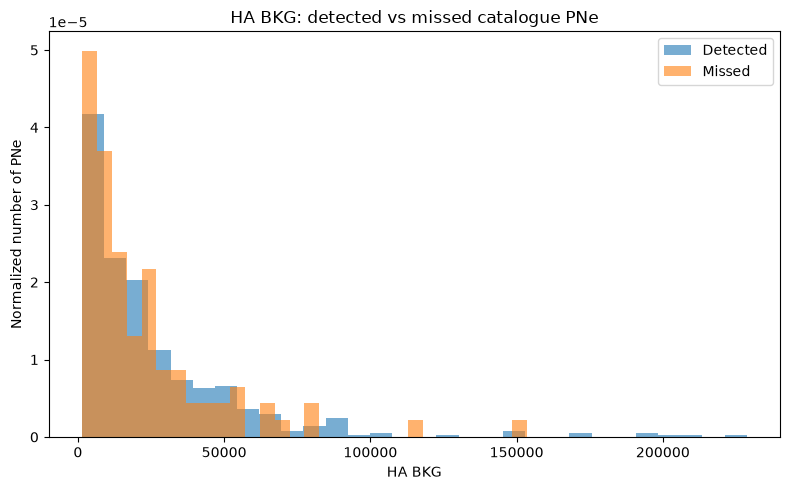

In [47]:
oiii_bkg_data = evaluated_catalog[np.isfinite(evaluated_catalog[OIII_BKG_COL])].copy()
detected_oiii_bkg = oiii_bkg_data.loc[oiii_bkg_data["detected_by_model"], OIII_BKG_COL]
missed_oiii_bkg = oiii_bkg_data.loc[~m5007_data["detected_by_model"], OIII_BKG_COL]

ha_bkg_data = evaluated_catalog[np.isfinite(evaluated_catalog[HA_BKG_COL])].copy()
detected_ha_bkg = ha_bkg_data.loc[ha_bkg_data["detected_by_model"], HA_BKG_COL]
missed_ha_bkg = ha_bkg_data.loc[~m5007_data["detected_by_model"], HA_BKG_COL]

print("OIII BKG statistics")
print("====================")
print(f"Detected: N={len(detected_oiii_bkg)}, median={np.median(detected_oiii_bkg):.2f}, mean={np.mean(detected_oiii_bkg):.2f}")
print(f"Missed:   N={len(missed_oiii_bkg)}, median={np.median(missed_oiii_bkg):.2f}, mean={np.mean(missed_oiii_bkg):.2f}")

print("HA BKG statistics")
print("====================")
print(f"Detected: N={len(detected_ha_bkg)}, median={np.median(detected_ha_bkg):.2f}, mean={np.mean(detected_ha_bkg):.2f}")
print(f"Missed:   N={len(missed_ha_bkg)}, median={np.median(missed_ha_bkg):.2f}, mean={np.mean(missed_ha_bkg):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_oiii_bkg, bins=30, alpha=0.6, density=True, label="Detected")
plt.hist(missed_oiii_bkg, bins=30, alpha=0.6, density=True, label="Missed")
plt.xlabel("OIII BKG")
plt.ylabel("Normalized number of PNe")
plt.title("OIII BKG: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(detected_ha_bkg, bins=30, alpha=0.6, density=True, label="Detected")
plt.hist(missed_ha_bkg, bins=30, alpha=0.6, density=True, label="Missed")
plt.xlabel("HA BKG")
plt.ylabel("Normalized number of PNe")
plt.title("HA BKG: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

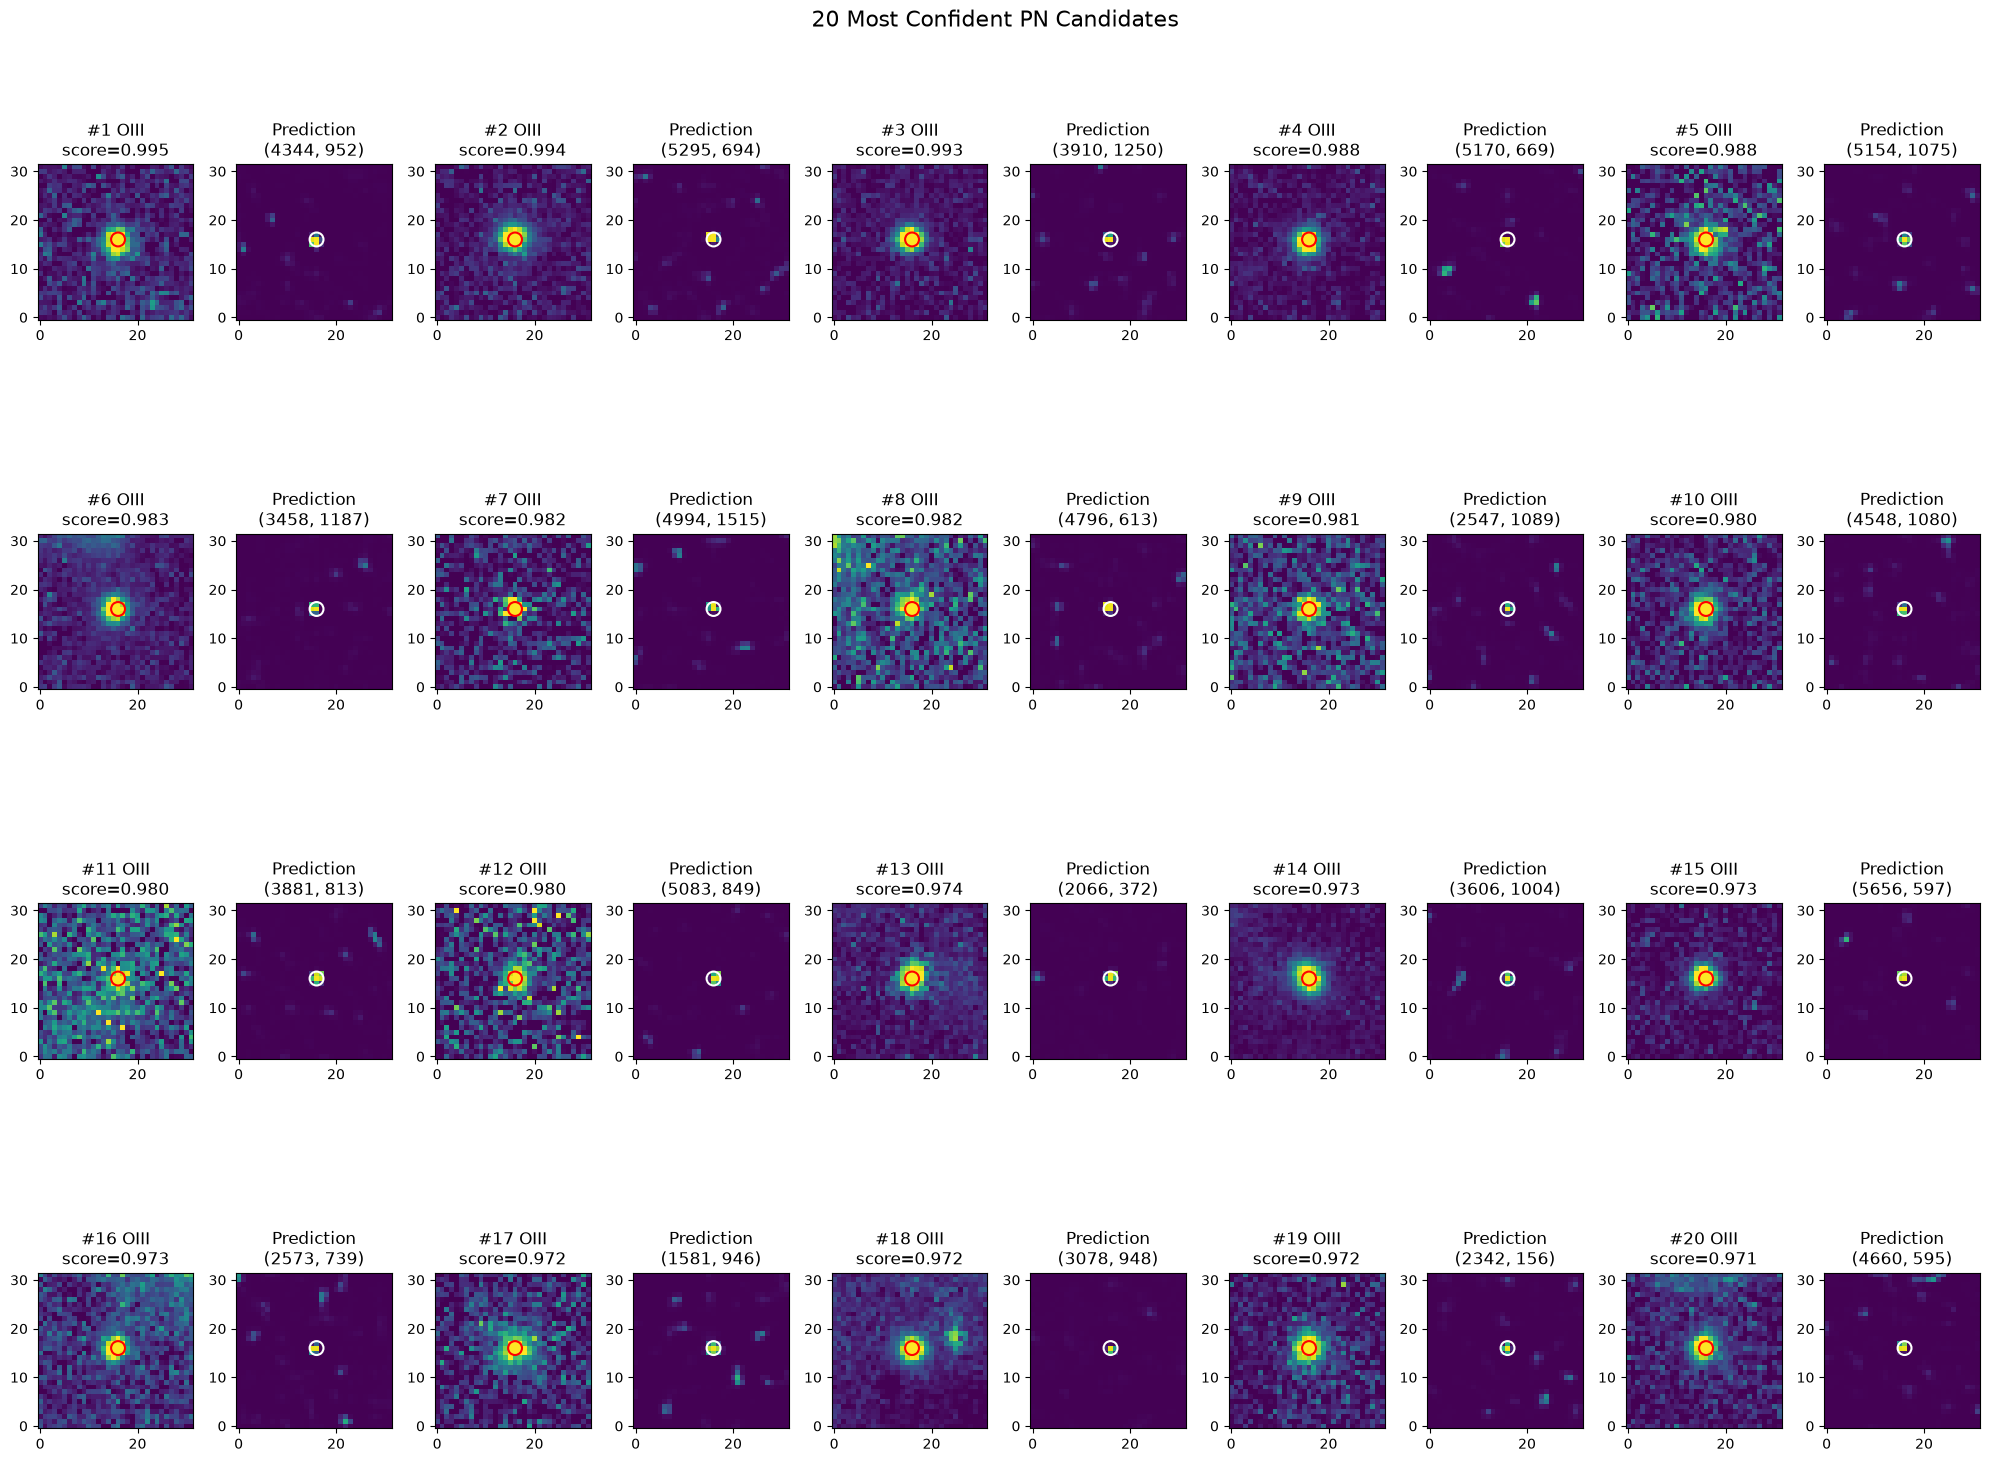

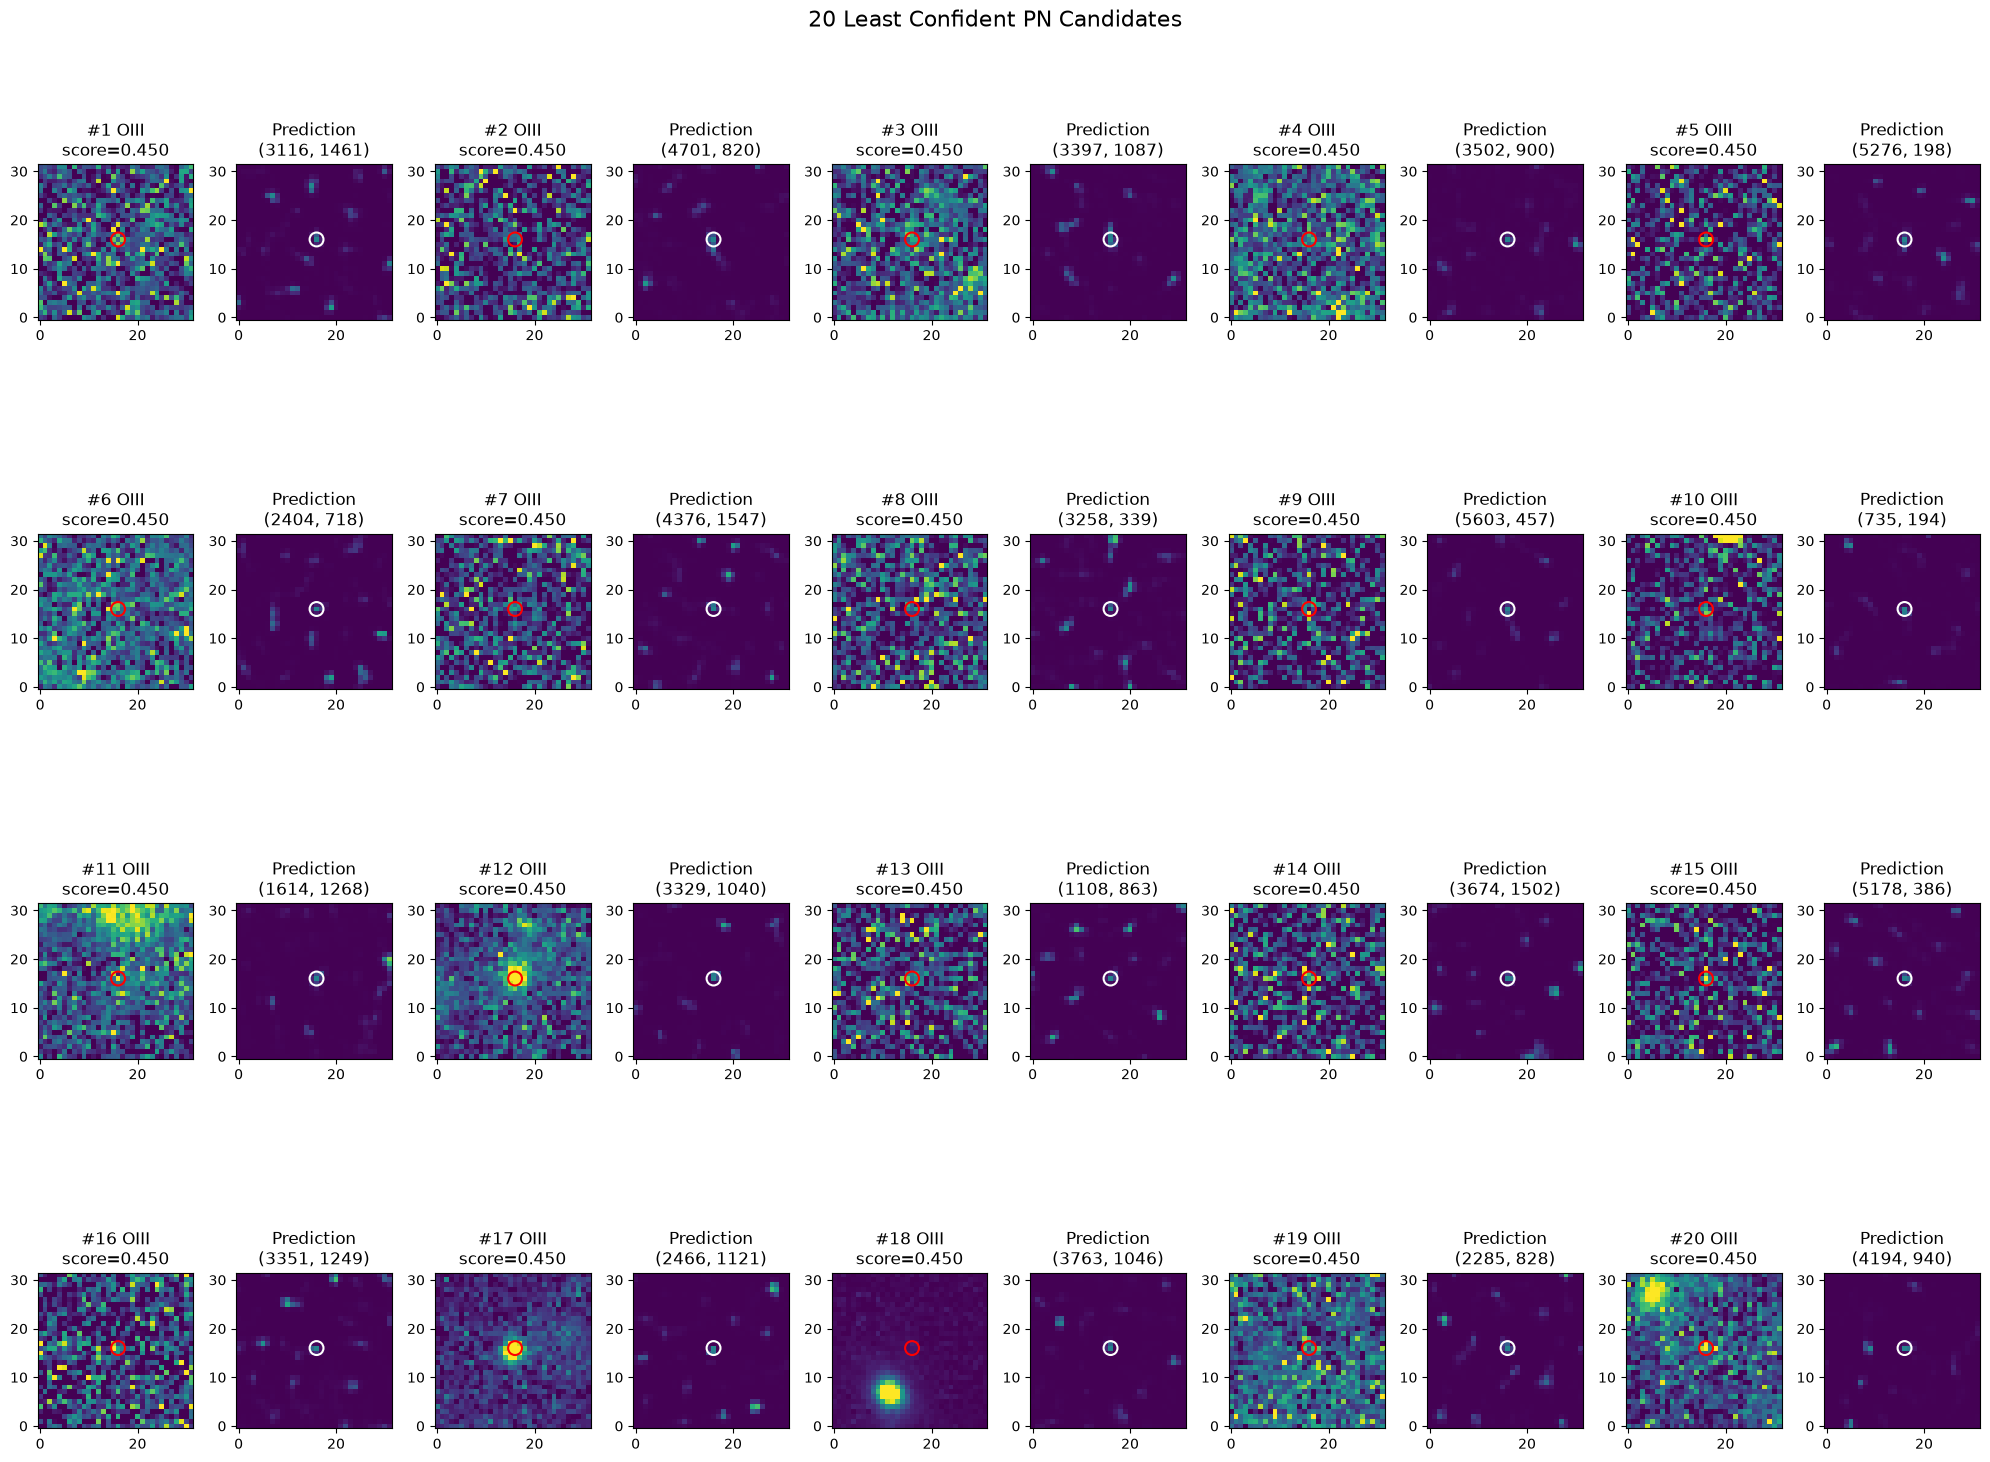

In [48]:
def plot_confidence_cutouts(image, pn_heatmap, detections, n_sources=20, cutout_size=32):
    oiii = image[..., 1]
    height, width = pn_heatmap.shape
    half = cutout_size // 2

    def plot_group(selected, title):
        n = len(selected)
        n_rows = int(np.ceil(n / 5))
        fig, axes = plt.subplots(n_rows, 10, figsize=(20, 4 * n_rows))
        axes = np.atleast_2d(axes)

        for i, (x, y, score) in enumerate(selected):
            x, y = int(round(x)), int(round(y))
            x0 = max(0, min(x - half, width - cutout_size))
            y0 = max(0, min(y - half, height - cutout_size))
            x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

            oiii_cutout = oiii[y0:y1, x0:x1]
            pred_cutout = pn_heatmap[y0:y1, x0:x1]
            local_x, local_y = x - x0, y - y0

            finite = oiii_cutout[np.isfinite(oiii_cutout)]
            vmin, vmax = np.percentile(finite, [8, 99]) if len(finite) else (0, 1)

            row, col = i // 5, (i % 5) * 2

            ax = axes[row, col]
            ax.imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="red", s=100, linewidths=1.5)
            ax.set_title(f"#{i + 1} OIII\nscore={score:.3f}")

            ax = axes[row, col + 1]
            ax.imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="white", s=100, linewidths=1.5)
            ax.set_title(f"Prediction\n({x}, {y})")

        for ax in axes.flat[2 * n:]:
            ax.axis("off")

        fig.suptitle(title, fontsize=16)
        plt.tight_layout()
        plt.show()

    n = min(n_sources, len(detections))
    plot_group(detections[:n], f"{n} Most Confident PN Candidates")
    plot_group(detections[-n:][::-1], f"{n} Least Confident PN Candidates")


plot_confidence_cutouts(
    image=image,
    pn_heatmap=pn_heatmap,
    detections=detections,
    n_sources=20,
    cutout_size=32
)